Load & Clean Dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the dataset
data_dir = Path("../data")
csv_files = list(data_dir.glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV in {data_dir}, found: {csv_files}"
    )

df = pd.read_csv(csv_files[0])

print("Dataset loaded:", csv_files[0].name)
print("Original shape:", df.shape)

# Convert blank strings in TotalCharges to proper missing values
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", np.nan, regex=True
)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("\nMissing values after cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Dataset loaded: dataWA_Fn-UseC_-Telco-Customer-Churn.csv
Original shape: (7043, 21)

Missing values after cleaning:
TotalCharges    11
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0


Investigate Churn Patterns

Overall churn rate: 26.54%

Churn rate by contract type:


,Churn_Rate_Percent
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


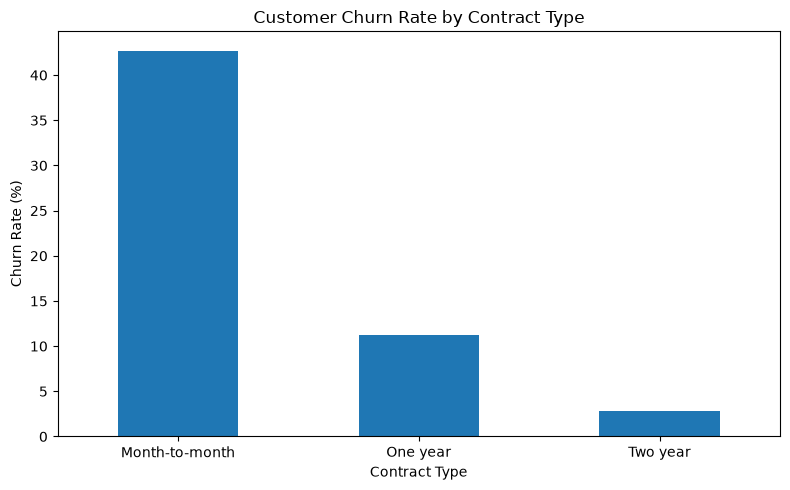

In [7]:
# Convert churn labels into a numeric indicator for analysis
df["Churn_Flag"] = df["Churn"].map({"Yes": 1, "No": 0})

# Overall churn rate
print(f"Overall churn rate: {df['Churn_Flag'].mean() * 100:.2f}%")

# Churn rate by contract type
contract_churn = (
    df.groupby("Contract")["Churn_Flag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("\nChurn rate by contract type:")
display(contract_churn.to_frame("Churn_Rate_Percent"))

# Visualize contract-level churn
contract_churn.plot(kind="bar", figsize=(8, 5))
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Explore Customer Tenure & Monthly Charges

Tenure by churn status:


,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


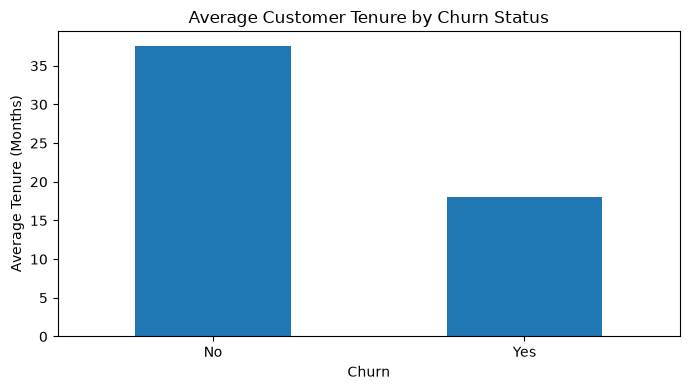


Monthly charges by churn status:


,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


In [8]:
# Compare tenure for customers who churned and stayed
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median"]
)

print("Tenure by churn status:")
display(tenure_summary.round(2))

tenure_summary["mean"].plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Compare monthly charges
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
)

print("\nMonthly charges by churn status:")
display(charges_summary.round(2))

Investigate Tenure Groups

Churn rate by tenure group:


,Churn_Rate_Percent
TenureGroup,
0–6 months,52.94
7–12 months,35.89
13–24 months,28.71
25–48 months,20.39
49+ months,9.51


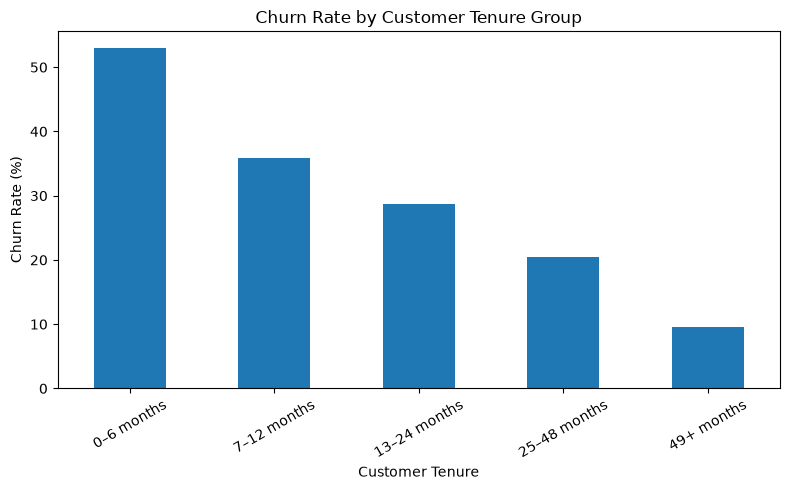

In [9]:
# Create customer tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, float("inf")],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49+ months"
    ]
)

# Calculate churn rate within each tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn_Flag"]
      .mean()
      .mul(100)
)

print("Churn rate by tenure group:")
display(tenure_churn.to_frame("Churn_Rate_Percent").round(2))

# Plot the results
tenure_churn.plot(kind="bar", figsize=(8, 5))
plt.title("Churn Rate by Customer Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()